# LAB 1

In [1]:
# import
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import MNIST, SVHN
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import os, time

## Conseguir la Data

In [2]:
transform_mnist = transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
transform_svhn = transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

In [3]:
mnist_train = MNIST(root='./data', train=True, download=False, transform=transform_mnist)
svhn_train  = SVHN(root='./data', split='train', download=False, transform=transform_svhn)

In [4]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize to pot
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

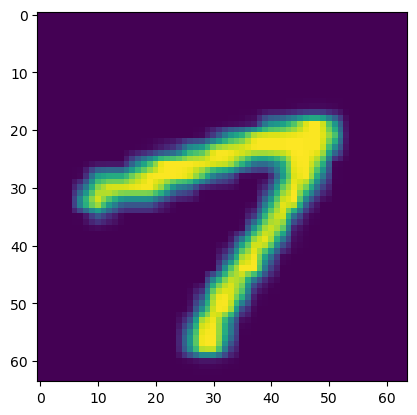

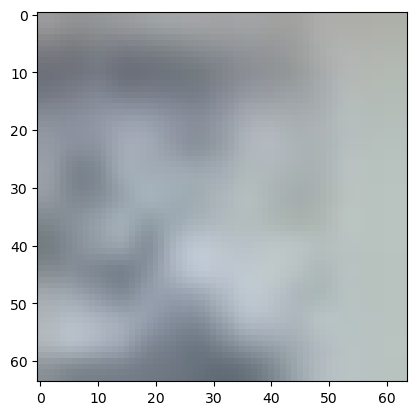

In [5]:
imshow(mnist_train[101][0])
imshow(svhn_train[101][0])


## 1. Agrupar la Data

In [5]:
class PairedMNISTSVHN(Dataset):
    def __init__(self, mnist_dataset, svhn_dataset):
        self.mnist = mnist_dataset
        self.svhn = svhn_dataset

        mnist_targets = np.array(self.mnist.targets)
        svhn_labels = np.array(self.svhn.labels)
        # SVHN usa la etiqueta 10 para representar el dígito 0 (quirk histórico del dataset)
        svhn_labels = np.where(svhn_labels == 10, 0, svhn_labels)
        self.svhn_labels = svhn_labels

        # índices de cada dataset agrupados por dígito (0-9)
        self.mnist_by_label = {d: np.where(mnist_targets == d)[0] for d in range(10)}
        self.svhn_by_label  = {d: np.where(svhn_labels == d)[0] for d in range(10)}

        # longitud "artificial" del dataset emparejado
        self.length = max(len(self.mnist), len(self.svhn))

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        digit = np.random.randint(0, 10)
        m_idx = np.random.choice(self.mnist_by_label[digit])
        s_idx = np.random.choice(self.svhn_by_label[digit])

        x_mnist, _ = self.mnist[m_idx]
        x_svhn, _  = self.svhn[s_idx]

        return x_mnist, x_svhn, digit

In [6]:
paired_dataset = PairedMNISTSVHN(mnist_train, svhn_train)
paired_loader = DataLoader(paired_dataset, batch_size=64, shuffle=True)

C:\Users\sampe\AppData\Local\Temp\ipykernel_37224\3222552724.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  mnist_targets = np.array(self.mnist.targets)


No son elementos únicos

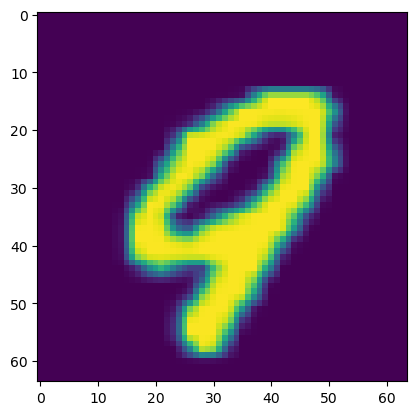

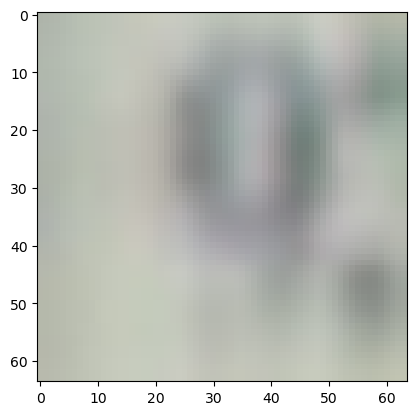

Dígito: 9


In [50]:
x_mnist, x_svhn, digit = paired_dataset[160]
imshow(x_mnist)
imshow(x_svhn)
print("Dígito:", digit)

In [51]:
x_m, x_s, labels = next(iter(paired_loader))
print(x_m.shape)   # [64, 1, 28, 28]  <- batch de 64 vectores-imagen de MNIST
print(x_s.shape)   # [64, 3, 32, 32]  <- batch de 64 vectores-imagen de SVHN

torch.Size([64, 1, 64, 64])
torch.Size([64, 3, 64, 64])


## Encoders and Decoders for each data type:

In [7]:
class encoder_s(nn.Module):
    
    def __init__(self,dimz,channels=3,var_x=0.1):
        
        # Red Neuronal
        
        super().__init__()
        
        self.dimz = dimz    #dimz is k, the dimension of the latent space

        # self.conv1 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1
        
        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=32, 
                               kernel_size=4, stride=2, padding=1)

        self.relu = nn.ReLU()
        
        # self.conv2 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32, 
                               kernel_size=4, stride=2, padding=1) #YOUR CODE HERE

        # self.conv3 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1  
        
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, 
                               kernel_size=4, stride=2, padding=1)      

        # self.conv4 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1  

        self.conv4 = nn.Conv2d(in_channels=64, out_channels=64, 
                               kernel_size=4, stride=2, padding=1) #YOUR CODE HERE

        # self.conv5 is a convolutional layer, with 256 output channels, kernel size 4, stride 1,
        # and padding 0                                
        
        self.conv5 = nn.Conv2d(in_channels=64, out_channels=256, 
                               kernel_size=4, stride=1, padding=0) 
        

        # self.linear is a linear layer with dimz*2 outputs
        self.linear = nn.Linear(256, dimz * 2) 
        
        self.softplus = nn.Softplus()
        
    def forward(self,x):

        # The forward method to project and image into a 2dimz dimensional vector
        
        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z)) #YOUR CODE HERE
        z = self.relu(self.conv3(z))
        z = self.relu(self.conv4(z)) #YOUR CODE HERE
        z = self.relu(self.conv5(z))
        # Transform z into a 256-dim vector
        z = z.view(-1,256) #YOUR CODE HERE
        z = self.linear(z)
        
        return z
    
    def encode_and_sample(self,x,flag_sample=True):

        # This methods compute both the posterior mean and variance
        # Also we obtain a sample from the posterior using the
        # reparameterization trick.

        # We obtain the encoder projection using the forward method
        
        z = self.forward(x)

        # The mean is the first dimz components of the forward output
        
        mu = z[:, :self.dimz] #YOUR CODE HERE

        # We compute the variance from the last dimz components using a 
        # soft plus
        var = self.softplus(0.5 * z[:, self.dimz:]) 
        
        sample = None
        
        if(flag_sample==True):
            
            eps = torch.randn_like(var) 
            
            sample = mu + eps*(var**0.5)
        
        return mu,var,sample
    

In [8]:
class decoder_s(nn.Module):
    
    def __init__(self,dimz,channels=3,var_x=0.1):
        
        super().__init__()

        # We expand z into a 256 dimensional vector 
        
        self.linear = nn.Linear(dimz,256)
        
        self.relu = nn.ReLU()

        self.tanh = nn.Tanh()

        # self.tconv1 is a convolutional layer, with 64 output channels, kernel size 4, stride 1,
        # and padding 0 
        
        self.tconv1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=1,padding=0)

        # self.tconv2 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1         
        
        self.tconv2 = nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1)#YOUR CODE HERE

        # self.tconv3 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1  
        
        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2,padding=1)

        # self.tconv3 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1
        
        self.tconv4 = nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2,padding=1)#YOUR CODE HERE

        # self.tconv3 is a convolutional layer, with channels output channels, kernel size 4, stride 2,
        # and padding 1        
        
        self.tconv5 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2,padding=1)
        
    def forward(self,z):

        x = self.relu(self.linear(z).view(-1,256,1,1))
        x = self.relu(self.tconv1(x))#YOUR CODE HERE
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))#YOUR CODE HERE
        x = self.relu(self.tconv4(x))
        x = self.tanh(self.tconv5(x))#YOUR CODE HERE   
        return x
    
    def decode(self,z):

        # This function simply calls the forward method
        
        return self.forward(z)

In [9]:
class encoder_m(nn.Module):
    
    def __init__(self,dimz,channels=1,var_x=0.1):
        
        # Red Neuronal
        
        super().__init__()
        
        self.dimz = dimz    #dimz is k, the dimension of the latent space

        # self.conv1 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1
        
        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=32, 
                               kernel_size=4, stride=2, padding=1)

        self.relu = nn.ReLU()
        
        # self.conv2 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32, 
                               kernel_size=4, stride=2, padding=1) #YOUR CODE HERE

        # self.conv3 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1  
        
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, 
                               kernel_size=4, stride=2, padding=1)      

        # self.conv4 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1  

        self.conv4 = nn.Conv2d(in_channels=64, out_channels=64, 
                               kernel_size=4, stride=2, padding=1) #YOUR CODE HERE

        # self.conv5 is a convolutional layer, with 256 output channels, kernel size 4, stride 1,
        # and padding 0                                
        
        self.conv5 = nn.Conv2d(in_channels=64, out_channels=256, 
                               kernel_size=4, stride=1, padding=0) 
        

        # self.linear is a linear layer with dimz*2 outputs
        self.linear = nn.Linear(256, dimz * 2) 
        
        self.softplus = nn.Softplus()
        
    def forward(self,x):

        # The forward method to project and image into a 2dimz dimensional vector
        
        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z)) #YOUR CODE HERE
        z = self.relu(self.conv3(z))
        z = self.relu(self.conv4(z)) #YOUR CODE HERE
        z = self.relu(self.conv5(z))
        # Transform z into a 256-dim vector
        z = z.view(-1,256) #YOUR CODE HERE
        z = self.linear(z)
        
        return z
    
    def encode_and_sample(self,x,flag_sample=True):

        # This methods compute both the posterior mean and variance
        # Also we obtain a sample from the posterior using the
        # reparameterization trick.

        # We obtain the encoder projection using the forward method
        
        z = self.forward(x)

        # The mean is the first dimz components of the forward output
        
        mu = z[:, :self.dimz] #YOUR CODE HERE

        # We compute the variance from the last dimz components using a 
        # soft plus
        var = self.softplus(0.5 * z[:, self.dimz:]) 
        
        sample = None
        
        if(flag_sample==True):
            
            eps = torch.randn_like(var) 
            
            sample = mu + eps*(var**0.5)
        
        return mu,var,sample

In [10]:
class decoder_m(nn.Module):
    
    def __init__(self,dimz,channels=1,var_x=0.1):
        
        super().__init__()

        # We expand z into a 256 dimensional vector 
        
        self.linear = nn.Linear(dimz,256)
        
        self.relu = nn.ReLU()

        self.tanh = nn.Tanh()

        # self.tconv1 is a convolutional layer, with 64 output channels, kernel size 4, stride 1,
        # and padding 0 
        
        self.tconv1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=1,padding=0)

        # self.tconv2 is a convolutional layer, with 64 output channels, kernel size 4, stride 2,
        # and padding 1         
        
        self.tconv2 = nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1)#YOUR CODE HERE

        # self.tconv3 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1  
        
        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2,padding=1)

        # self.tconv3 is a convolutional layer, with 32 output channels, kernel size 4, stride 2,
        # and padding 1
        
        self.tconv4 = nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2,padding=1)#YOUR CODE HERE

        # self.tconv3 is a convolutional layer, with channels output channels, kernel size 4, stride 2,
        # and padding 1        
        
        self.tconv5 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2,padding=1)
        
    def forward(self,z):

        x = self.relu(self.linear(z).view(-1,256,1,1))
        x = self.relu(self.tconv1(x))#YOUR CODE HERE
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))#YOUR CODE HERE
        x = self.relu(self.tconv4(x))
        x = self.tanh(self.tconv5(x))#YOUR CODE HERE   
        return x
    
    def decode(self,z):

        # This function simply calls the forward method
        
        return self.forward(z)

## Loss function

In [11]:
def eval_Gaussian_LL(x,mu_x,var_x):

    # x is a mini-batch of images. It has dimension [Batch,3,dimx,dimx]

    # mu_x is a mini-batch of reconstructed images. It has dimension [Batch,3,dimx,dimx]

    # var_x is a torch constant

    D = x.shape[1] * x.shape[2] * x.shape[3]   # Dimension of the image

    x = x.reshape(-1, D)

    mu_x = mu_x.reshape(-1, D)

    var_x = torch.ones_like(mu_x) * var_x

    # Constant term in the gaussian distribution
    cnt = D * np.log(2 * np.pi) + torch.sum(torch.log(var_x), dim=-1)

    # log-likelihood per datapoint

    logp_data = -0.5 * (cnt + torch.sum((x - mu_x) * var_x ** -1 * (x - mu_x), dim=-1))
    
    # Accumulated Gaussian log-likelihood for all datapoints in the batch
    logp = torch.sum(logp_data)

    return logp,logp_data

In [12]:
# ---------------------------------------------------------------
# Funciones auxiliares (van FUERA de la clase, junto a eval_Gaussian_LL)
# eval_Gaussian_LL NO sirve para z: espera imagenes 4D y varianza constante.
# ---------------------------------------------------------------
def log_normal_diag(z, mu, var):
    """log N(z; mu, diag(var)).  z, mu, var: [B, dimz] -> [B]"""
    return -0.5 * torch.sum(np.log(2 * np.pi) + torch.log(var) + (z - mu) ** 2 / var, dim=-1)
 
 
def log_normal_std(z):
    """log N(z; 0, I) = log p(z), el prior.  z: [B, dimz] -> [B]"""
    return -0.5 * torch.sum(np.log(2 * np.pi) + z ** 2, dim=-1)
 
 
def log_mixture(z, mus, vars_):
    """
    log q(z) = log( sum_m (1/M) N(z; mu_m, var_m) ), evaluada en z.
    mus, vars_: listas de M tensores [B, dimz]  ->  [B]
    logsumexp: con dimz=50 exp(log-densidad) hace underflow en float32.
    """
    logs = torch.stack([log_normal_diag(z, m, v) for m, v in zip(mus, vars_)], dim=0)  # [M, B]
    return torch.logsumexp(logs, dim=0) - np.log(len(mus))

Ver si hacemos una loss function para poe y moe y comparamos rendimientos

## 2. MultiVAE Class

In [ ]:
class Multi_VAE(nn.Module):

    def __init__(self, dimz=int,  channels_s=3, channels_m=1, var_x_s=0.1, var_x_m=0.1,lr=1e-3,epochs=100,save_folder='./',restore=False):
        
        super().__init__()

        self.var_x_s = var_x_s
        self.var_x_m = var_x_m
        self.dimz = dimz

        # We create an encoder network
        self.encoder_s = encoder_s(self.dimz,channels_s,self.var_x_s) #YOUR CODE HERE
        self.encoder_m = encoder_m(self.dimz,channels_m,self.var_x_m) #YOUR CODE HERE
        # We create a decoder network
        self.decoder_s = decoder_s(self.dimz,channels_s,self.var_x_s) #YOUR CODE HERE
        self.decoder_m = decoder_m(self.dimz,channels_m,self.var_x_m) #YOUR CODE HERE

        self.lr = lr    
        self.optim = optim.Adam(self.parameters(), self.lr)   
        self.epochs = epochs

        self.save_folder = save_folder

        if(restore==True):
                 state_dict = torch.load(self.save_folder + 'MultiVAE_MoE.pth',
                                         map_location=torch.device('cpu'))
                 self.load_state_dict(state_dict)

        self.loss_during_training = []
        self.reconstruc_during_training = []
        self.KL_during_training = []

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.to(self.device)

    def forward_moe(self, x_mnist, x_svhn):
        # Encode MNIST
        mu_m, var_m, z_m = self.encoder_m.encode_and_sample(x_mnist)
        # Encode SVHN
        mu_s, var_s, z_s = self.encoder_s.encode_and_sample(x_svhn)

        # Samples
        mu_m_dec_m = self.decoder_m.decode(z_m)
        mu_m_dec_s = self.decoder_s.decode(z_m) 
        mu_s_dec_m = self.decoder_m.decode(z_s)
        mu_s_dec_s = self.decoder_s.decode(z_s)

        samples = (mu_m_dec_m, mu_m_dec_s, mu_s_dec_m, mu_s_dec_s)

        # z_m y z_s tambien hacen falta: log p(z) y log q(z) se evaluan EN z, no en mu
        return samples, (mu_m, mu_s), (var_m, var_s), (z_m, z_s)

    def loss_function_moe(self, x_mnist, x_svhn, samples, mus, vars_, zs):
        mu_m_dec_m, mu_m_dec_s, mu_s_dec_m, mu_s_dec_s = samples
        z_m, z_s = zs

        # ---- termino del experto M (z_m) ----
        logp_mm, _ = eval_Gaussian_LL(x_mnist, mu_m_dec_m, self.var_x_m)  # decoder_m vs x_mnist
        logp_ms, _ = eval_Gaussian_LL(x_svhn,  mu_m_dec_s, self.var_x_s)  # decoder_s vs x_svhn
        kl_m = torch.sum(log_mixture(z_m, mus, vars_) - log_normal_std(z_m))  # log q - log p(z), MC
        loss_m = -logp_mm - logp_ms + kl_m

        # ---- termino del experto S (z_s) ----
        logp_sm, _ = eval_Gaussian_LL(x_mnist, mu_s_dec_m, self.var_x_m)  # decoder_m vs x_mnist
        logp_ss, _ = eval_Gaussian_LL(x_svhn,  mu_s_dec_s, self.var_x_s)  # decoder_s vs x_svhn
        kl_s = torch.sum(log_mixture(z_s, mus, vars_) - log_normal_std(z_s))
        loss_s = -logp_sm -logp_ss + kl_s

        loss = (loss_m + loss_s) / 2                       # muestreo estratificado: media de M terminos
        rec = -(logp_mm + logp_ms + logp_sm + logp_ss) / 2  # NLL de reconstruccion (positivo)
        recs_s = [logp_mm, logp_ms, logp_sm, logp_ss]
        kls_s = [kl_m, kl_s]

        # Guardar la reconstrucción de cada decoder

        kl = (kl_m + kl_s) / 2

        return loss, rec, recs_s, kl


    def trainloop(self,trainloader):

        nims = len(trainloader.dataset)

        self.train()

        self.rec_mm_s = []  # Decoder MNIST desde z_m
        self.rec_ms_s = []  # Decoder SVHN desde z_m
        self.rec_sm_s = []  # Decoder MNIST desde z_s
        self.rec_ss_s = []  # Decoder SVHN desde z_s

        self.kl_m_s = []    # KL del experto MNIST
        self.kl_s_s = []    # KL del experto SVHN

        for e in range(int(self.epochs)):

            train_loss = 0
            train_rec = 0
            train_kl_l = 0

            idx_batch = 0

            for x_mnist, x_svhn, digit in trainloader:

                x_mnist = x_mnist.to(self.device)
                x_svhn = x_svhn.to(self.device)
                self.optim.zero_grad()

                ##################### POE #####################

                #mu_x_mnist, mu_x_svhn, mu_poe, var_poe = self.forward_poe(x_mnist, x_svhn)

                #loss, rec_m, rec_s, kl_z = slef.loss_function_poe(x_mnist, x_svhn, mu_x_mnist, mu_x_svhn, mu_poe, var_poe) 

                ##################### MOE #####################

                recs, mus, vars_, zs = self.forward_moe(x_mnist, x_svhn)
                loss, rec, kl_z, recs_s, kls_s = self.loss_function_moe(x_mnist, x_svhn, recs, mus, vars_, zs)

                # Guardar cada término por separado, para cada batch
                self.rec_mm_s.append(recs_s[0].item())
                self.rec_ms_s.append(recs_s[1].item())
                self.rec_sm_s.append(recs_s[2].item())
                self.rec_ss_s.append(recs_s[3].item())

                self.kl_m_s.append(kls_s[0].item())
                self.kl_s_s.append(kls_s[1].item())

                loss.backward()

                train_loss += loss.item()
                train_rec += rec.item()
                train_kl_l += kl_z.item() 

                self.optim.step()

                if(idx_batch%10==0):

                    torch.save(self.state_dict(), self.save_folder + 'MultiVAE_MoE.pth')

                idx_batch += 1

            self.loss_during_training.append(train_loss/len(trainloader))
            self.reconstruc_during_training.append(train_rec/len(trainloader))
            self.KL_during_training.append(train_kl_l/len(trainloader))


            if(e%1==0):

                torch.save(self.state_dict(), self.save_folder + 'MultiVAE_MoE.pth')
                print('Train Epoch: {} \tLoss: {:.6f}'.format(e,self.loss_during_training[-1]))

    def sample(self, num_imgs):
        with torch.no_grad():
            eps = torch.randn([num_imgs, self.dimz]).to(self.device)
            x_s = self.decoder_s.decode(eps).cpu()
            x_m = self.decoder_m.decode(eps).cpu()
            return x_s, x_m    


    def cross_sample(self,x_mnist=None, x_svhn=None):
        self.eval()
        with torch.no_grad():
            if x_mnist is not None:
                x_mnist = x_mnist.to(self.device)
                mu_m, _, _ = self.encoder_m.encode_and_sample(x_mnist, flag_sample=False)
                # MNIST -> espacio latente -> SVHN
                return self.decoder_s.decode(mu_m).cpu()
            elif x_svhn is not None:
                x_svhn = x_svhn.to(self.device)
                mu_s, _, _ = self.encoder_s.encode_and_sample(x_svhn, flag_sample=False)
                # SVHN -> espacio latente -> MNIST
                return self.decoder_m.decode(mu_s).cpu()
            else:
                raise ValueError("Debes proporcionar x_mnist o x_svhn.")

            
    def sample_from_posterior(self, x_mnist=None, x_svhn=None):
        """
        Muestrea desde el posterior q(z|x) de una modalidad dada y lo decodifica.
        """
        self.eval()
        with torch.no_grad():
            if x_mnist is not None:
                x_mnist = x_mnist.to(self.device)
                # Obtenemos el sample z_m muestreado del posterior q(z_m | x_mnist)
                _, _, z_m = self.encoder_m.encode_and_sample(x_mnist, flag_sample=True)
                rec_m = self.decoder_m.decode(z_m).cpu()  # MNIST -> MNIST
                cross_s = self.decoder_s.decode(z_m).cpu() # MNIST -> SVHN
                return rec_m, cross_s

            elif x_svhn is not None:
                x_svhn = x_svhn.to(self.device)
                # Obtenemos el sample z_s muestreado del posterior q(z_s | x_svhn)
                _, _, z_s = self.encoder_s.encode_and_sample(x_svhn, flag_sample=True)
                rec_s = self.decoder_s.decode(z_s).cpu()  # SVHN -> SVHN
                cross_m = self.decoder_m.decode(z_s).cpu() # SVHN -> MNIST
                return rec_s, cross_m

            else:
                raise ValueError("Debes proporcionar x_mnist o x_svhn.")           


## 3. Projection into the shared latent space can be made through a product or mixture of experts.

In [20]:
# Create my Multi_VAE instance
path_to_save = './saved_multi_vae/'
os.makedirs(path_to_save, exist_ok=True)      # torch.save falla si la carpeta no existe


In [23]:
path_to_save = os.path.expanduser('~/saved_multi_vae/')   # p. ej. C:\Users\<tu_usuario>\saved_multi_vae\
os.makedirs(path_to_save, exist_ok=True)

In [24]:
my_multivae = Multi_VAE(dimz=50, channels_s=3, channels_m=1,
                        var_x_s=0.1, var_x_m=0.1,
                        lr=1e-3, epochs=70,
                        save_folder=path_to_save, restore=False)

In [25]:
# PairedMNISTSVHN.__getitem__ ignora idx y empareja al azar, asi que un Subset
# da parejas nuevas en cada epoca: 6400 parejas = 100 batches de 64.
trainloader = DataLoader(Subset(paired_dataset, range(6400)), batch_size=64, shuffle=True)
my_multivae.trainloop(trainloader)

Train Epoch: 0 	Loss: 351038.533906
Train Epoch: 1 	Loss: 249705.503281
Train Epoch: 2 	Loss: 229259.170313
Train Epoch: 3 	Loss: 216996.718906
Train Epoch: 4 	Loss: 215177.603750
Train Epoch: 5 	Loss: 207622.347031
Train Epoch: 6 	Loss: 201001.903125
Train Epoch: 7 	Loss: 196240.354531
Train Epoch: 8 	Loss: 189004.621250
Train Epoch: 9 	Loss: 186757.011406
Train Epoch: 10 	Loss: 182823.058750
Train Epoch: 11 	Loss: 185816.365469
Train Epoch: 12 	Loss: 183426.935625
Train Epoch: 13 	Loss: 181303.098125
Train Epoch: 14 	Loss: 179509.231094
Train Epoch: 15 	Loss: 164633.661641
Train Epoch: 16 	Loss: 35799.238672
Train Epoch: 17 	Loss: -17230.864102
Train Epoch: 18 	Loss: -38548.146719
Train Epoch: 19 	Loss: -48264.153906
Train Epoch: 20 	Loss: -54432.933008
Train Epoch: 21 	Loss: -59329.915703
Train Epoch: 22 	Loss: -62997.131875
Train Epoch: 23 	Loss: -65262.958437
Train Epoch: 24 	Loss: -67695.029063
Train Epoch: 25 	Loss: -70049.660000
Train Epoch: 26 	Loss: -70924.874531
Train Epoch:

In [ ]:
# Guardar los pesos del modelo
torch.save(
    my_multivae.state_dict(),
    path_to_save + 'MultiVAE_MoE.pth'
)

# Guardar el historial del entrenamiento
torch.save({
    'loss': my_multivae.loss_during_training,
    'rec':  my_multivae.reconstruc_during_training,
    'kl':   my_multivae.KL_during_training,

    # Reconstrucciones individuales
    'rec_mm_s': my_multivae.rec_mm_s,
    'rec_ms_s': my_multivae.rec_ms_s,
    'rec_sm_s': my_multivae.rec_sm_s,
    'rec_ss_s': my_multivae.rec_ss_s,

    # KL individuales
    'kl_m_s': my_multivae.kl_m_s,
    'kl_s_s': my_multivae.kl_s_s
}, path_to_save + 'MultiVAE_MoE_history.pth')

In [32]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

state = torch.load(
    path_to_save + 'MultiVAE_MoE.pth',
    map_location=device,
    weights_only=True
)

my_multivae.load_state_dict(state)

# 3. Enviar el modelo al dispositivo y ponerlo en modo evaluación
my_multivae = my_multivae.to(device)
my_multivae.eval()

Multi_VAE(
  (encoder_s): encoder_s(
    (conv1): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (relu): ReLU()
    (conv2): Conv2d(32, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (conv3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (conv4): Conv2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (conv5): Conv2d(64, 256, kernel_size=(4, 4), stride=(1, 1))
    (linear): Linear(in_features=256, out_features=100, bias=True)
    (softplus): Softplus(beta=1.0, threshold=20.0)
  )
  (encoder_m): encoder_m(
    (conv1): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (relu): ReLU()
    (conv2): Conv2d(32, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (conv3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (conv4): Conv2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (conv5): Conv2d(64, 256, kernel_size=(4, 4), stride=(1, 1))
    (linear): Linea

In [22]:
history = torch.load(
    path_to_save + 'MultiVAE_MoE_history.pth',
    map_location='cpu',
    weights_only=True
)

rec_mm_s = history['rec_mm_s']
rec_ms_s = history['rec_ms_s']
rec_sm_s = history['rec_sm_s']
rec_ss_s = history['rec_ss_s']

kl_m_s = history['kl_m_s']
kl_s_s = history['kl_s_s']

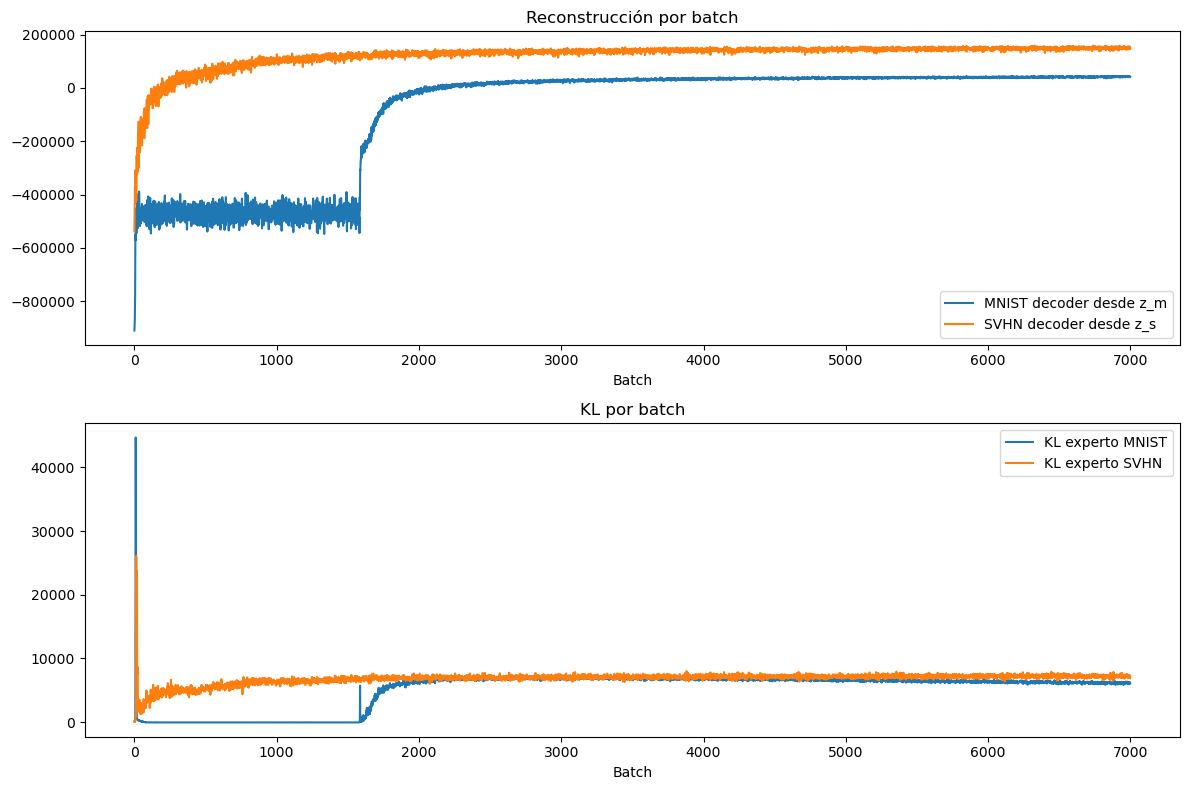

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(my_multivae.rec_mm_s, label='MNIST decoder desde z_m')
ax[0].plot(my_multivae.rec_ms_s, label='SVHN decoder desde z_m')
ax[0].plot(my_multivae.rec_sm_s, label='MNIST decoder desde z_s')
ax[0].plot(my_multivae.rec_ss_s, label='SVHN decoder desde z_s')
ax[0].set_title('Reconstrucción por batch')
ax[0].set_xlabel('Batch')
ax[0].legend()

ax[1].plot(my_multivae.kl_m_s, label='KL experto MNIST')
ax[1].plot(my_multivae.kl_s_s, label='KL experto SVHN')
ax[1].set_title('KL por batch')
ax[1].set_xlabel('Batch')
ax[1].legend()

plt.tight_layout()
plt.show()

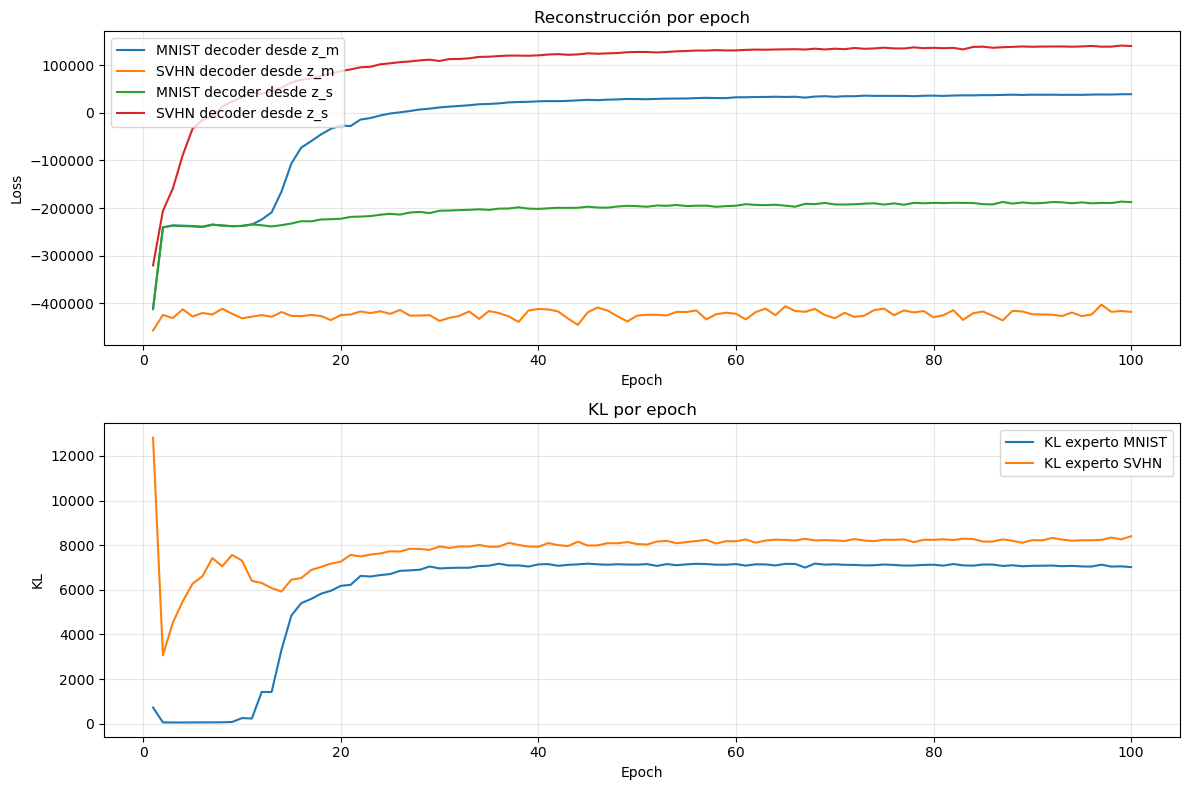

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# Número de batches por epoch
num_epochs = 100
batches_per_epoch = len(my_multivae.rec_mm_s) // num_epochs

def mean_by_epoch(values, batches_per_epoch):
    values = np.asarray(values)
    n = len(values) // batches_per_epoch
    return values[:n * batches_per_epoch].reshape(
        n, batches_per_epoch
    ).mean(axis=1)

# Reconstrucciones por epoch
rec_mm = mean_by_epoch(my_multivae.rec_mm_s, batches_per_epoch)
rec_ms = mean_by_epoch(my_multivae.rec_ms_s, batches_per_epoch)
rec_sm = mean_by_epoch(my_multivae.rec_sm_s, batches_per_epoch)
rec_ss = mean_by_epoch(my_multivae.rec_ss_s, batches_per_epoch)

# KL por epoch
kl_m = mean_by_epoch(my_multivae.kl_m_s, batches_per_epoch)
kl_s = mean_by_epoch(my_multivae.kl_s_s, batches_per_epoch)

epochs = np.arange(1, len(rec_mm) + 1)

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(epochs, rec_mm, label='MNIST decoder desde z_m')
ax[0].plot(epochs, rec_ms, label='SVHN decoder desde z_m')
ax[0].plot(epochs, rec_sm, label='MNIST decoder desde z_s')
ax[0].plot(epochs, rec_ss, label='SVHN decoder desde z_s')
ax[0].set_title('Reconstrucción por epoch')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(epochs, kl_m[:len(epochs)], label='KL experto MNIST')
ax[1].plot(epochs, kl_s[:len(epochs)], label='KL experto SVHN')
ax[1].set_title('KL por epoch')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('KL')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

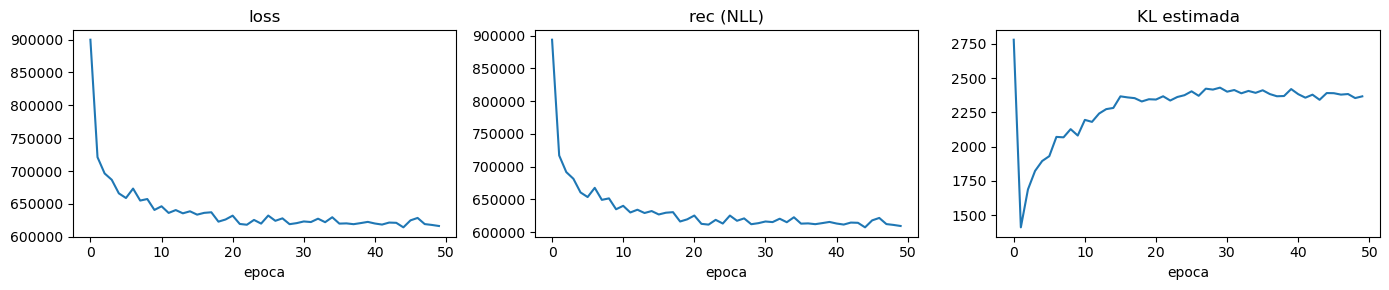

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, (name, h) in zip(ax, [('loss', my_multivae.loss_during_training),
                             ('rec (NLL)', my_multivae.reconstruc_during_training),
                             ('KL estimada', my_multivae.KL_during_training)]):
    a.plot(h); a.set_title(name); a.set_xlabel('epoca')
plt.tight_layout(); plt.show()

Esta loss es un conjunto de cosas, concretamente cómo recrea mnist y svhn los diferenets decoders pero no podemos saber si uno domina sobre otro ni cómo el aprendizaje de estos va evolucionando.

La Kl implica cómo funciona el encoder

## 4. Examples

### 4.1. Reconstruction:

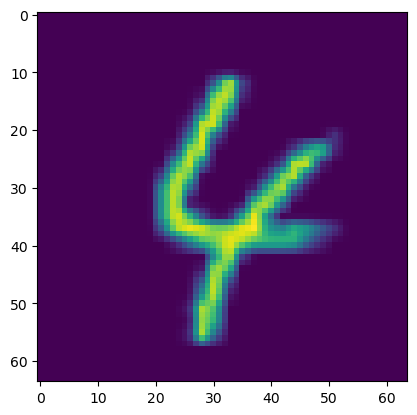

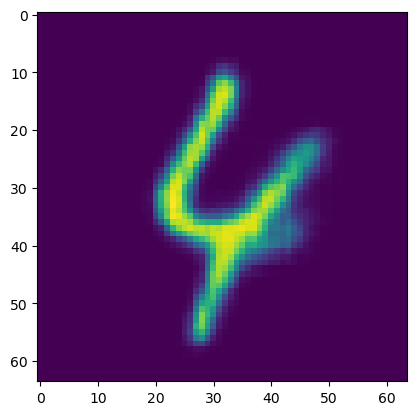

In [29]:
x_mnist, _, digit = paired_dataset[5]
i = x_mnist.unsqueeze(0)


z_batch,_,_ = my_multivae.encoder_m.encode_and_sample(x=i.to(my_multivae.device),flag_sample=False) # YOUR CODE HERE

x_reconstructed = my_multivae.decoder_m.decode(z_batch).detach() # YOUR CODE HERE

# We plot he original image
# YOUR CODE HERE
imshow(i[0,:,:,:].to('cpu'))
# And the reconstruction
# YOUR CODE HERE
imshow(x_reconstructed[0,:,:,:].to('cpu'))

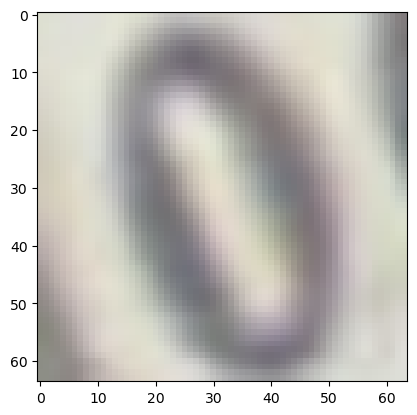

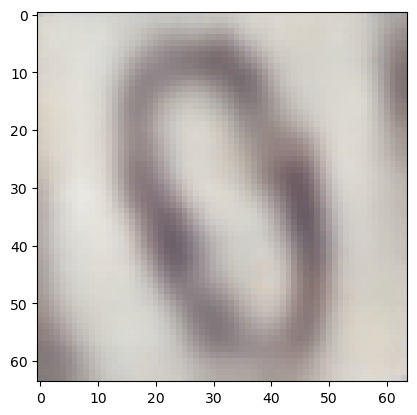

In [30]:
_, x_svhn, digit = paired_dataset[7]
i = x_svhn.unsqueeze(0)


z_batch,_,_ = my_multivae.encoder_s.encode_and_sample(x=i.to(my_multivae.device),flag_sample=False) # YOUR CODE HERE

x_reconstructed = my_multivae.decoder_s.decode(z_batch).detach() # YOUR CODE HERE

# We plot he original image
# YOUR CODE HERE
imshow(i[0,:,:,:].to('cpu'))
# And the reconstruction
# YOUR CODE HERE
imshow(x_reconstructed[0,:,:,:].to('cpu'))

### 4.2. Generation from latent space:

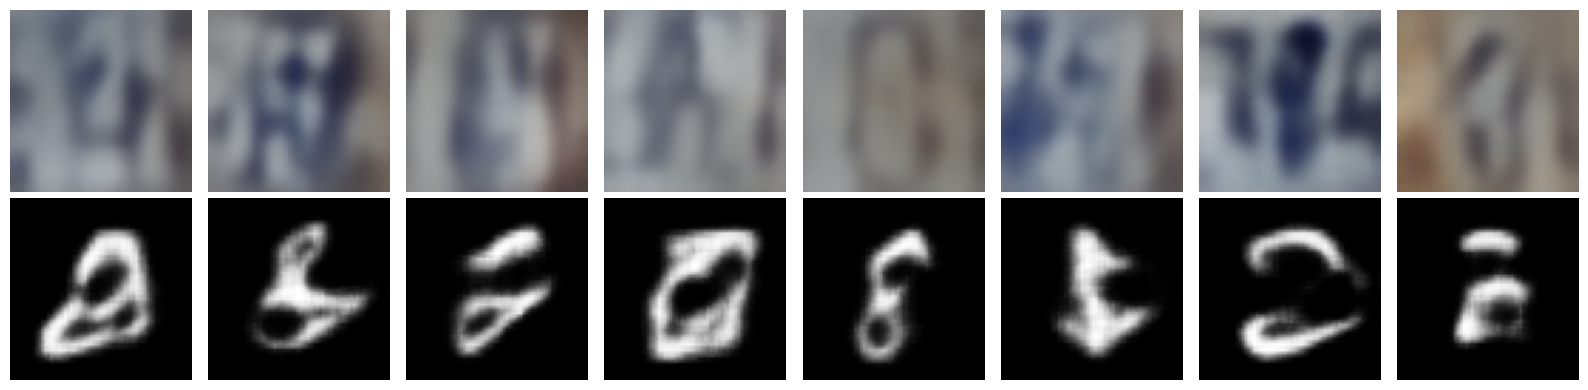

In [31]:
xs, xm = my_multivae.sample(8)

fig, ax = plt.subplots(2, 8, figsize=(16, 4))

for j in range(8):
    # SVHN: desnormalizar de [-1, 1] a [0, 1]
    img_svhn = xs[j].detach().cpu().permute(1, 2, 0)
    img_svhn = (img_svhn + 1) / 2
    img_svhn = img_svhn.clamp(0, 1)

    ax[0, j].imshow(img_svhn)
    ax[0, j].axis('off')

    # MNIST
    img_mnist = xm[j].detach().cpu().squeeze()
    ax[1, j].imshow(img_mnist, cmap='gray')
    ax[1, j].axis('off')

ax[0, 0].set_ylabel('SVHN ~ prior', fontsize=12)
ax[1, 0].set_ylabel('MNIST ~ prior (mismo z)', fontsize=12)

plt.tight_layout()
plt.show()

In [92]:
print("SVHN:", xs.min().item(), xs.max().item())
print("MNIST:", xm.min().item(), xm.max().item())

SVHN: -0.8441256284713745 0.205740287899971
MNIST: -1.0 0.916506826877594


### 4.3. Cross-domain generation:

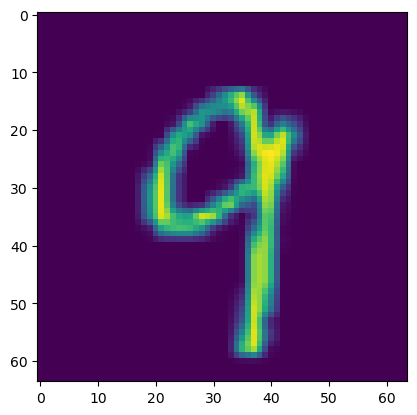

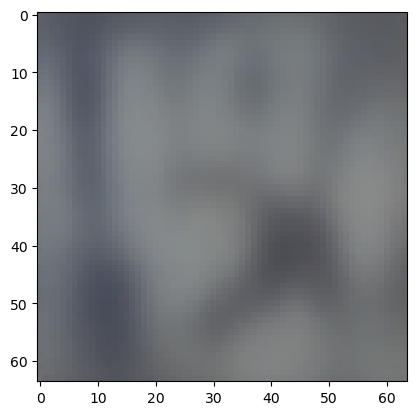

In [ ]:
# MNIST -> SVHN
x_mnist, _, digit = paired_dataset[0]
x_mnist = x_mnist.unsqueeze(0)

x_svhn_generated = my_multivae.cross_sample(
    x_mnist=x_mnist, x_svhn=None
)

imshow(x_mnist[0])
imshow(x_svhn_generated[0])

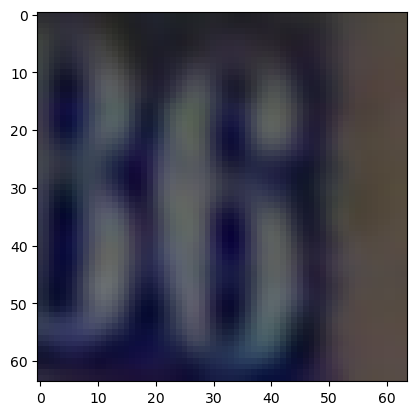

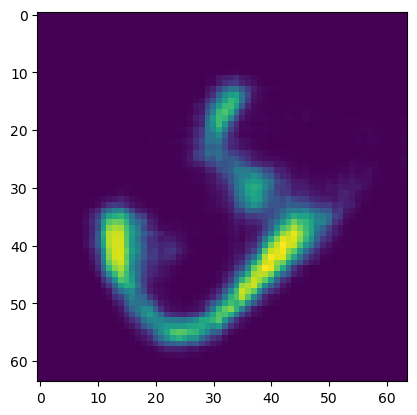

In [33]:
# SVHN -> MNIST
_, x_svhn, digit = paired_dataset[0]
x_svhn = x_svhn.unsqueeze(0)

x_mnist_generated = my_multivae.cross_sample(
    x_svhn=x_svhn, x_mnist=None
)

imshow(x_svhn[0])
imshow(x_mnist_generated[0])

## 5. Visualize the latent space through the t-SNE method.

In [104]:
sample = paired_dataset[0]

for j, item in enumerate(sample):
    if torch.is_tensor(item):
        print(j, item.shape)
    else:
        print(j, type(item))

0 torch.Size([1, 64, 64])
1 torch.Size([3, 64, 64])
2 <class 'int'>


In [32]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def rescale(img):
    img = img / 2 + 0.5     # unnormalize to pot
    npimg = img.numpy()
    return np.transpose(npimg, (1, 2, 0))
 
def plot_latent_space_with_images(images,latent,xmin=-5,xmax=5,ymin=-5,ymax=5):
 
    # images --> Minibatch of images (numpy array!)
    # latent --> Matrix of 2D representations (numpy array!)
 
    f, ax = plt.subplots(1,1,figsize=(8, 8))
    # ax is a figure handle
    ax.clear()
    for i in range(len(images)):
        im = OffsetImage(rescale(images[i,:,:,:]))
        ab = AnnotationBbox(im, latent[i,:],frameon=False)
        ax.add_artist(ab)
    #We set the limits according to the maximum and minimum values found for the latent projections
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax.set_title('Latent space Z with Images')

In [24]:
# Obtener 100 imágenes SVHN
x_svhn = torch.stack([
    paired_dataset[j][1] for j in range(100)
]).to(my_multivae.device)

# Obtener sus representaciones latentes
with torch.no_grad():
    z_batch, _, _ = my_multivae.encoder_s.encode_and_sample(
        x=x_svhn,
        flag_sample=False
    )

print(z_batch.shape)

# Reducir a 2 dimensiones
latent_tsne = TSNE(
    n_components=2,
).fit_transform(z_batch.detach().cpu().numpy())

torch.Size([100, 50])


c:\Users\sampe\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\sampe\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\sampe\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sampe\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

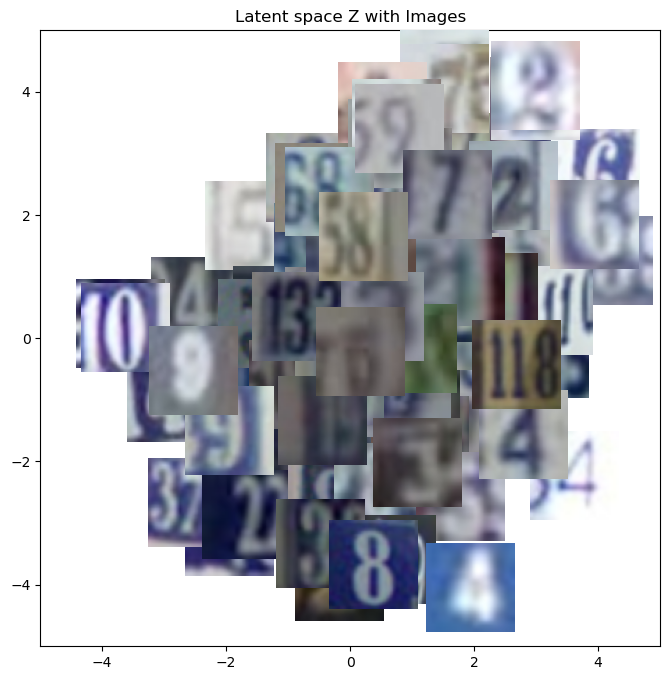

In [33]:
plot_latent_space_with_images(x_svhn.cpu(), latent_tsne)

In [34]:
# Obtener 100 imágenes SVHN
x_mnist = torch.stack([
    paired_dataset[j][0] for j in range(100)
]).to(my_multivae.device)

# Obtener sus representaciones latentes
with torch.no_grad():
    z_batch, _, _ = my_multivae.encoder_m.encode_and_sample(
        x=x_mnist,
        flag_sample=False
    )

print(z_batch.shape)

# Reducir a 2 dimensiones
latent_tsne = TSNE(
    n_components=2,
).fit_transform(z_batch.detach().cpu().numpy())

torch.Size([100, 50])


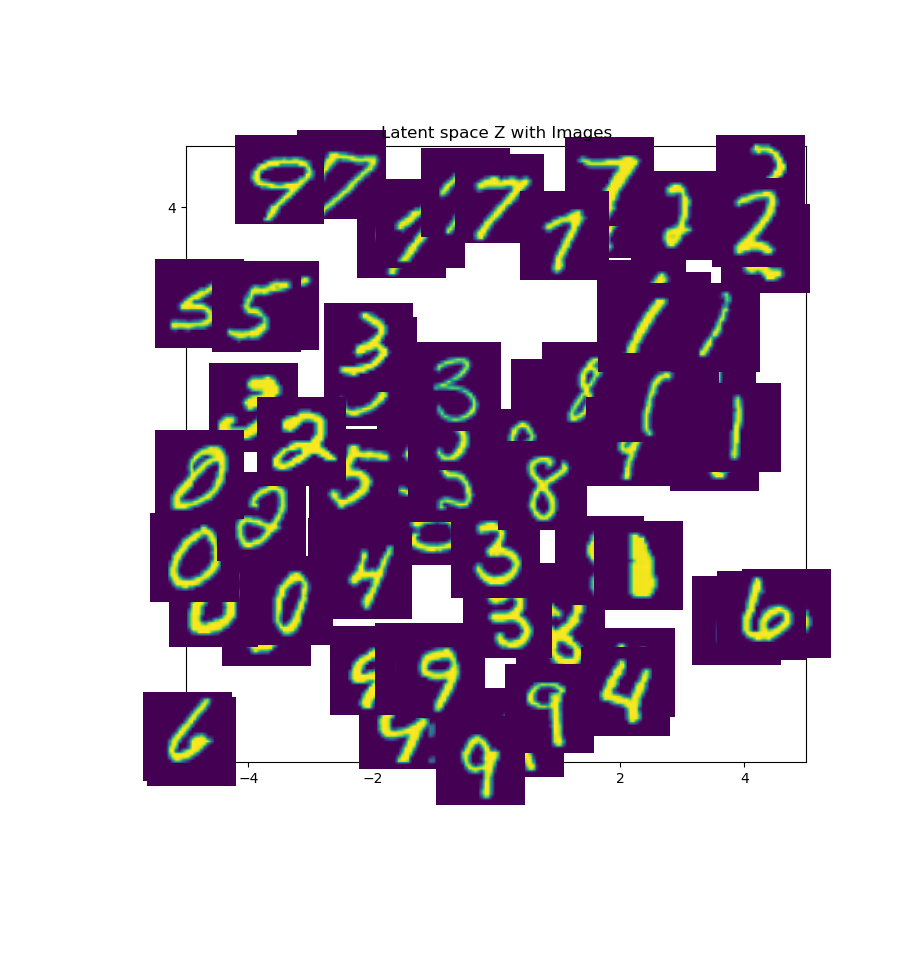

In [35]:
plot_latent_space_with_images(x_mnist.cpu(), latent_tsne)